In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
import os

print(os.getcwd())
print(os.listdir("data"))

c:\Users\Sneha Mishra\OneDrive\Desktop\Customer_churn_prediction
['archive', 'archive.zip', 'WA_Fn-UseC_-Telco-Customer-Churn.csv']


In [6]:
df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (7043, 21)


In [7]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [ ]:
df.describe().T #Statistical summary of numerical features

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


In [12]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [16]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [18]:
(df.astype(str).apply(
    lambda col: 
col.str.strip()).eq("")).sum()
#Check for empty strings in the dataset
#spaces count is not counted as null values, so we need to check for empty strings as well


customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [19]:
print(df.dtypes)

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


In [20]:
print(df["Churn"].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [21]:
print(df["Churn"].value_counts(normalize=True)*100) #Percentage of churned and non-churned customers

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [23]:
blank_charges = df[df["TotalCharges"].astype(str).str.strip().eq("")]

blank_charges[["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


from the above data we understood that the these customers have 0 tenure that means these are new customers so there total charges has not been recorded. 
we will create all 11 blank values to actual missing values

In [24]:
df["TotalCharges"] = df["TotalCharges"].replace(r"^\s*$", np.nan, regex=True)

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Missing Totalcharges:", df["TotalCharges"].isnull().sum())

Missing Totalcharges: 11


In [25]:
print(df["TotalCharges"].dtype)
print(df["TotalCharges"].isnull().sum())

float64
11


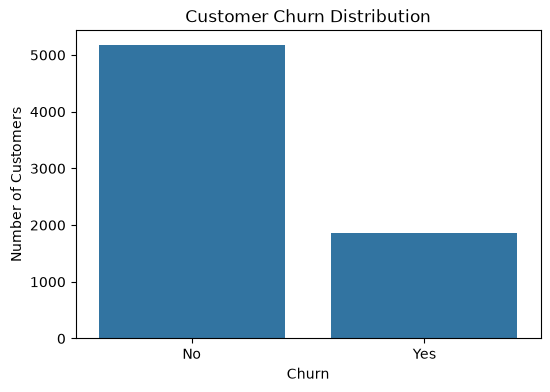

In [26]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

In [27]:
#customers kitne time se comapany ke sath hai and unka monthly charges kya hai, aur unhone total kitna pay kiya hai

df[["tenure", "MonthlyCharges", "TotalCharges"]].describe().T

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80


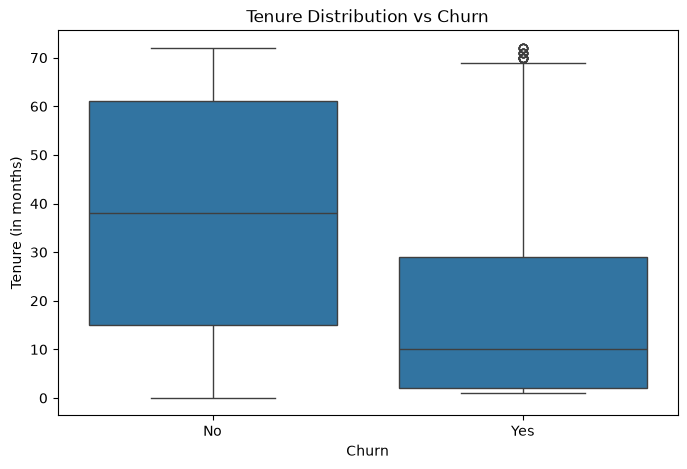

In [28]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("Tenure Distribution vs Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (in months)")
plt.show()

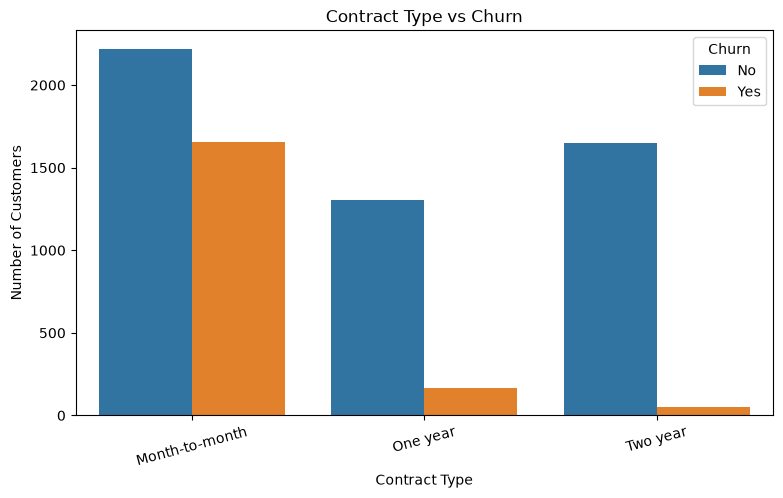

In [29]:
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Contract Type vs Churn")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.show()

In [30]:
contract_churn = pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100

print(contract_churn.round(2))

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


In [31]:
x = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].map({"Yes": 1, "No": 0}) #Convert target variable to binary

print("Features shape:", x.shape)
print("Target shape:", y.shape)

print(y.value_counts())

Features shape: (7043, 19)
Target shape: (7043,)
Churn
0    5174
1    1869
Name: count, dtype: int64


In [32]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

print("x_train shape:", x_train.shape)
print("x_test shape:", x_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

x_train shape: (5634, 19)
x_test shape: (1409, 19)
y_train shape: (5634,)
y_test shape: (1409,)


In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

In [9]:
numerical_features = x.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = x.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
print("Numerical features:", numerical_features)
print("no. of numerical features:", len(numerical_features))

print("Categorical features:", categorical_features)
print("no. of categorical features:", len(categorical_features))


NameError: name 'x' is not defined

In [6]:
#numerical preprocessing pipeline
numerical_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])

NameError: name 'SimpleImputer' is not defined

In [5]:
#categorical preprocessing pipeline
categorical_pipeline = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("encoder", OneHotEncoder(handle_unknown="ignore"))])

NameError: name 'SimpleImputer' is not defined

In [4]:
#combine both
preprocessor = ColumnTransformer([("num", numerical_pipeline, numerical_features), ("cat", categorical_pipeline, categorical_features)])

NameError: name 'ColumnTransformer' is not defined

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier",
LogisticRegression(max_iter=1000))
])

NameError: name 'preprocessor' is not defined

In [40]:
model.fit(x_train, y_train)

print("Model training completed!")

Model training completed!


In [41]:
y_pred = model.predict(x_test)

print("First 10 actual values:")
print(y_test.iloc[:10].tolist())

print("First 10 predicted values:")
print(y_pred[:10].tolist())

First 10 actual values:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 1]
First 10 predicted values:
[0, 1, 0, 0, 0, 1, 0, 0, 0, 0]


In [42]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-Score:", f1_score(y_test, y_pred))

print("\nclassification report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8055358410220014
precision: 0.6572327044025157
Recall: 0.5588235294117647
F1-Score: 0.6040462427745664

classification report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



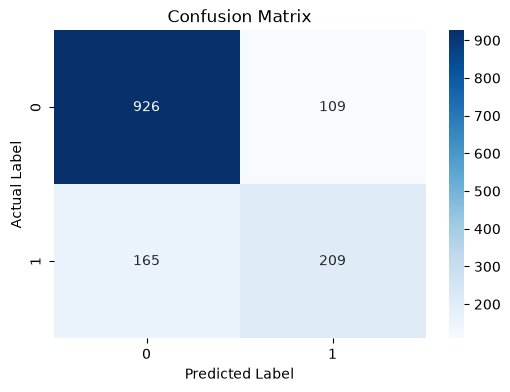

In [44]:
#confusion matrix

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

#RandomForest

In [2]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("Classifier",
RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
))
])

rf_model.fit(x_train, y_train)

print("Random forest training completed!")



NameError: name 'preprocessor' is not defined